# Day 103 — Forward Propagation | How a Neural Network Predicts Output

Forward propagation is the process of pushing an input through the network, layer by layer, to get a prediction.

In this notebook we will:
1. Walk through a **hand-calculable example** (3 → 2 → 2 → 1)
2. Write a **general forward function** with a cache
3. Build a small **NeuralNetwork class** with a summary
4. Compare **loops vs vectorization vs batches** (speed)
5. Use different **output heads**: sigmoid, softmax, linear, with their losses
6. Cross-check against **scikit-learn**
7. Handle **numerical stability**
8. **Visualize** activations flowing through the network

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_regression
from sklearn.neural_network import MLPClassifier, MLPRegressor

np.random.seed(42)

def sigmoid(z): return 1 / (1 + np.exp(-z))
def relu(z):    return np.maximum(0, z)

## 1. A hand-calculable example: 3 → 2 → 2 → 1

Story: predict whether a student gets placed from three scaled features: `x = [CGPA, IQ, 12th marks] = [0.8, 0.6, 0.9]`.

- Hidden layer 1 and 2: **ReLU**
- Output layer: **sigmoid** (probability of placement)

Notation (Day 101): `z^l = a^{l-1} W^l + b^l`, `a^l = f(z^l)`, `a^0 = x`.

In [2]:
x = np.array([[0.8, 0.6, 0.9]])                 # shape (1, 3)

W1 = np.array([[0.2, 0.5], [0.4, -0.3], [0.1, 0.6]]); b1 = np.array([0.1, -0.1])   # 3 -> 2
W2 = np.array([[0.3, -0.2], [0.5, 0.4]]);              b2 = np.array([0.05, 0.1])  # 2 -> 2
W3 = np.array([[0.7], [-0.4]]);                         b3 = np.array([0.1])        # 2 -> 1

# Layer 1
z1 = x @ W1 + b1
a1 = relu(z1)
print("z1 =", z1.round(4), "-> a1 =", a1.round(4))
print("  check node 1 by hand: 0.8*0.2 + 0.6*0.4 + 0.9*0.1 + 0.1 =", round(0.8*0.2 + 0.6*0.4 + 0.9*0.1 + 0.1, 4))

# Layer 2
z2 = a1 @ W2 + b2
a2 = relu(z2)
print("z2 =", z2.round(4), "-> a2 =", a2.round(4))

# Output layer
z3 = a2 @ W3 + b3
y_hat = sigmoid(z3)
print("z3 =", z3.round(4), "-> y_hat =", y_hat.round(4))
print("\nPredicted probability of placement:", round(float(y_hat[0, 0]), 4), "-> class", int(y_hat[0, 0] >= 0.5))

z1 = [[0.59 0.66]] -> a1 = [[0.59 0.66]]
  check node 1 by hand: 0.8*0.2 + 0.6*0.4 + 0.9*0.1 + 0.1 = 0.59
z2 = [[0.557 0.246]] -> a2 = [[0.557 0.246]]
z3 = [[0.3915]] -> y_hat = [[0.5966]]

Predicted probability of placement: 0.5966 -> class 1


## 2. A general forward function (with a cache)

We keep `z^l` and `a^l` for every layer, because backpropagation (coming soon) needs them.

In [3]:
def forward(X, params, activations):
    # params: list of (W, b); activations: list of functions (one per layer)
    A = X
    cache = [("a0", A)]
    for l, ((W, b), f) in enumerate(zip(params, activations), start=1):
        Z = A @ W + b
        A = f(Z)
        cache.append((f"z{l}", Z)); cache.append((f"a{l}", A))
    return A, cache

params = [(W1, b1), (W2, b2), (W3, b3)]
acts = [relu, relu, sigmoid]

out, cache = forward(x, params, acts)
print("Output:", out.round(4))
print("Cache keys:", [k for k, _ in cache])
print("Matches the step-by-step result:", np.allclose(out, y_hat))

Output: [[0.5966]]
Cache keys: ['a0', 'z1', 'a1', 'z2', 'a2', 'z3', 'a3']
Matches the step-by-step result: True


## 3. A small NeuralNetwork class

Includes weight initialization (He for ReLU, Xavier for sigmoid/tanh), `forward`, `predict` and a Keras-style `summary`.

In [4]:
class NeuralNetwork:
    def __init__(self, layer_sizes, activations, seed=0):
        rng = np.random.RandomState(seed)
        self.sizes, self.acts = layer_sizes, activations
        self.params = []
        for l in range(1, len(layer_sizes)):
            n_in, n_out = layer_sizes[l - 1], layer_sizes[l]
            scale = np.sqrt(2.0 / n_in) if activations[l - 1] is relu else np.sqrt(1.0 / n_in)
            self.params.append((rng.randn(n_in, n_out) * scale, np.zeros(n_out)))

    def forward(self, X):
        A = X
        for (W, b), f in zip(self.params, self.acts):
            A = f(A @ W + b)
        return A

    def summary(self):
        print(f"{'Layer':>6} | {'Output shape':>13} | {'Params':>6} | Activation")
        total = 0
        for l, ((W, b), f) in enumerate(zip(self.params, self.acts), start=1):
            p = W.size + b.size; total += p
            print(f"{l:6d} | {str((None, W.shape[1])):>13} | {p:6d} | {f.__name__}")
        print("Total parameters:", total)

net = NeuralNetwork([3, 8, 4, 1], [relu, relu, sigmoid])
net.summary()
print("\nForward on a batch of 5 samples ->", net.forward(np.random.randn(5, 3)).shape)

 Layer |  Output shape | Params | Activation
     1 |     (None, 8) |     32 | relu
     2 |     (None, 4) |     36 | relu
     3 |     (None, 1) |      5 | sigmoid
Total parameters: 73

Forward on a batch of 5 samples -> (5, 1)


## 4. Loops vs vectorization vs batches

The same computation written three ways. Matrix multiplication is what GPUs are built for.

In [5]:
net_big = NeuralNetwork([100, 256, 128, 1], [relu, relu, sigmoid])
X_big = np.random.randn(1000, 100)

def forward_loops(x_row, net):
    a = list(x_row)
    for (W, b), f in zip(net.params, net.acts):
        z = [sum(a[i] * W[i, j] for i in range(W.shape[0])) + b[j] for j in range(W.shape[1])]
        a = [float(f(np.array(zj))) for zj in z]
    return a

# 1. python loops, one sample at a time (only 20 samples, it is slow)
t0 = time.perf_counter()
out_loops = [forward_loops(X_big[i], net_big) for i in range(20)]
t_loops = (time.perf_counter() - t0) / 20

# 2. vectorized, one sample at a time
t0 = time.perf_counter()
out_vec = [net_big.forward(X_big[i:i+1]) for i in range(1000)]
t_vec = (time.perf_counter() - t0) / 1000

# 3. vectorized, whole batch at once
t0 = time.perf_counter()
out_batch = net_big.forward(X_big)
t_batch = (time.perf_counter() - t0) / 1000

print(f"Python loops       : {t_loops * 1e3:9.4f} ms per sample")
print(f"Vectorized (1 row) : {t_vec * 1e3:9.4f} ms per sample")
print(f"Vectorized (batch) : {t_batch * 1e3:9.4f} ms per sample")
print(f"Speed-up of loops -> batch: about {t_loops / t_batch:,.0f}x")
print("Results agree:", np.allclose(out_loops[0][0], out_batch[0, 0]))

Python loops       :   89.7704 ms per sample
Vectorized (1 row) :    0.1696 ms per sample
Vectorized (batch) :    0.0280 ms per sample
Speed-up of loops -> batch: about 3,203x
Results agree: True


## 5. Output heads: what the last layer looks like

| Task | Output layer | Prediction | Loss |
|---|---|---|---|
| Binary classification | 1 node, **sigmoid** | `p >= 0.5` | Binary cross entropy |
| Multi-class | K nodes, **softmax** | `argmax` | Categorical cross entropy |
| Regression | 1 node, **linear** (no activation) | the value | MSE |

In [6]:
def softmax(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True))        # subtract max for stability
    return e / e.sum(axis=1, keepdims=True)

identity = lambda z: z
identity.__name__ = "linear"

X_demo = np.random.randn(4, 5)
rng = np.random.RandomState(1)

# --- binary
net_bin = NeuralNetwork([5, 6, 1], [relu, sigmoid], seed=1)
p = net_bin.forward(X_demo).ravel()
y_bin = np.array([1, 0, 1, 0])
bce = -(y_bin * np.log(p) + (1 - y_bin) * np.log(1 - p)).mean()
print("Binary      : probabilities =", p.round(3), "| classes =", (p >= 0.5).astype(int), "| BCE =", round(bce, 4))

# --- multi-class
net_mc = NeuralNetwork([5, 6, 3], [relu, softmax], seed=2)
P = net_mc.forward(X_demo)
y_mc = np.array([0, 2, 1, 2])
cce = -np.log(P[np.arange(4), y_mc]).mean()
print("Multi-class : row sums =", P.sum(axis=1).round(3), "| classes =", P.argmax(axis=1), "| CE =", round(cce, 4))

# --- regression
net_reg = NeuralNetwork([5, 6, 1], [relu, identity], seed=3)
y_pred = net_reg.forward(X_demo).ravel()
y_true = np.array([0.5, -1.0, 2.0, 0.0])
print("Regression  : predictions =", y_pred.round(3), "| MSE =", round(((y_pred - y_true) ** 2).mean(), 4))

Binary      : probabilities = [0.205 0.321 0.31  0.301] | classes = [0 0 0 0] | BCE = 0.8754
Multi-class : row sums = [1. 1. 1. 1.] | classes = [1 1 1 1] | CE = 2.8168
Regression  : predictions = [-0.973  0.767 -0.034  1.057] | MSE = 2.6368


## 6. Cross-check against scikit-learn

We take the weights learned by `MLPClassifier` / `MLPRegressor` and reproduce their predictions with our own forward pass.

In [7]:
# Multi-class classifier (scikit-learn uses ReLU hidden units and a softmax output)
X_mc, y_mc_data = make_blobs(n_samples=300, centers=3, cluster_std=1.5, random_state=0)
clf = MLPClassifier(hidden_layer_sizes=(8, 5), activation="relu", max_iter=2000, random_state=0).fit(X_mc, y_mc_data)

params_sk = list(zip(clf.coefs_, clf.intercepts_))
mine, _ = forward(X_mc, params_sk, [relu, relu, softmax])
print("Classifier: max |our proba - sklearn proba| =", np.abs(mine - clf.predict_proba(X_mc)).max())
print("Classifier: same predicted classes:", np.array_equal(mine.argmax(axis=1), clf.predict(X_mc)))

# Regressor (linear output)
X_r, y_r = make_regression(n_samples=200, n_features=4, noise=5, random_state=0)
reg = MLPRegressor(hidden_layer_sizes=(10,), activation="relu", max_iter=3000, random_state=0).fit(X_r, y_r)
mine_r, _ = forward(X_r, list(zip(reg.coefs_, reg.intercepts_)), [relu, identity])
print("Regressor : max |our prediction - sklearn prediction| =", np.abs(mine_r.ravel() - reg.predict(X_r)).max())

Classifier: max |our proba - sklearn proba| = 0.0
Classifier: same predicted classes: True
Regressor : max |our prediction - sklearn prediction| = 0.0


c:\Users\DELL\.conda\envs\akhil\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


## 7. Numerical stability

Large scores can overflow `exp`. Subtracting the maximum before `exp` (softmax) or splitting by sign (sigmoid) fixes it.

In [8]:
scores = np.array([[1000.0, 1001.0, 1002.0]])

with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)
print("Naive softmax :", naive)
print("Stable softmax:", softmax(scores).round(4))

def sigmoid_stable(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1 / (1 + np.exp(-z[pos]))
    e = np.exp(z[~pos]); out[~pos] = e / (1 + e)
    return out

with np.errstate(over="ignore"):
    print("\nNaive sigmoid(-1000):", 1 / (1 + np.exp(1000.0)), "(works here but overflows internally and warns)")
print("Stable sigmoid(-1000):", sigmoid_stable(np.array([-1000.0]))[0])

Naive softmax : [[nan nan nan]]
Stable softmax: [[0.09   0.2447 0.6652]]

Naive sigmoid(-1000): 0.0 (works here but overflows internally and warns)
Stable sigmoid(-1000): 0.0


## 8. Watching activations flow through a trained network

We train a small network on the moons data and look at the hidden activations for one sample from each class.

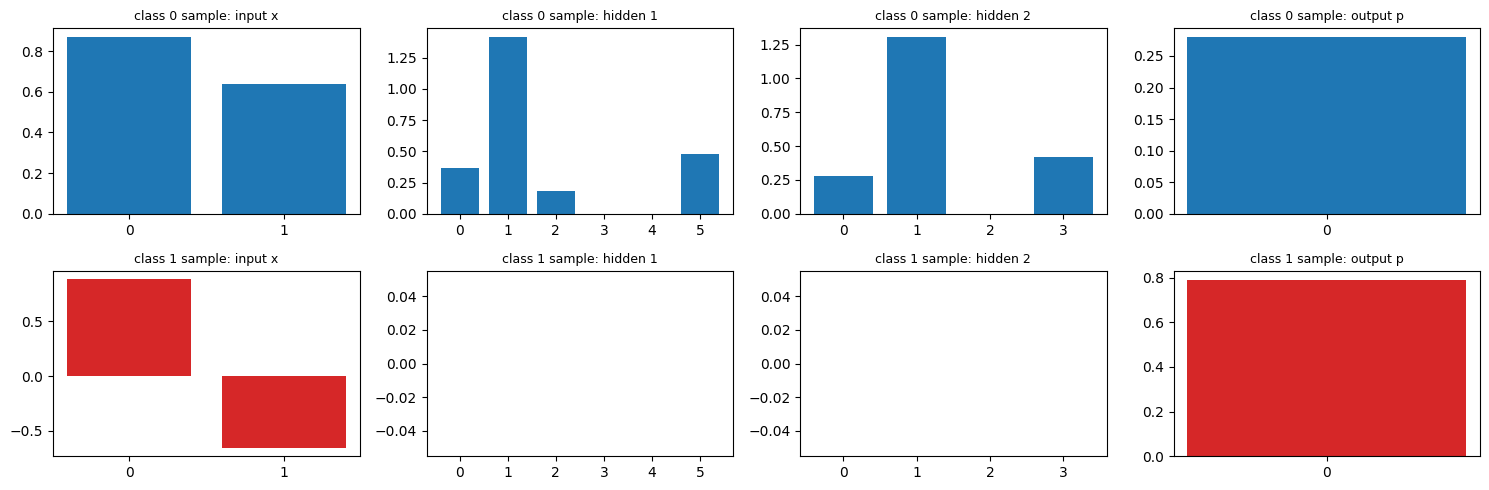

Output probability of class 1 -> class 0 sample: 0.28 | class 1 sample: 0.79


In [9]:
X_m, y_m = make_moons(n_samples=300, noise=0.2, random_state=0)
moons_net = MLPClassifier(hidden_layer_sizes=(6, 4), activation="relu", max_iter=3000, random_state=0).fit(X_m, y_m)
p_moons = list(zip(moons_net.coefs_, moons_net.intercepts_))

i0, i1 = np.where(y_m == 0)[0][0], np.where(y_m == 1)[0][0]
samples = X_m[[i0, i1]]
_, cache = forward(samples, p_moons, [relu, relu, sigmoid])
layers = [("input x", cache[0][1])] + [(f"hidden {k}", dict(cache)[f"a{k}"]) for k in (1, 2)] + [("output p", dict(cache)["a3"])]

fig, axes = plt.subplots(2, 4, figsize=(15, 5))
for r, (idx, label) in enumerate([(0, "class 0 sample"), (1, "class 1 sample")]):
    for c, (name, A) in enumerate(layers):
        axes[r, c].bar(range(A.shape[1]), A[idx], color="tab:blue" if r == 0 else "tab:red")
        axes[r, c].set_title(f"{label}: {name}", fontsize=9)
        axes[r, c].set_xticks(range(A.shape[1]))
plt.tight_layout(); plt.show()
print("Output probability of class 1 -> class 0 sample:", dict(cache)["a3"][0, 0].round(3), "| class 1 sample:", dict(cache)["a3"][1, 0].round(3))

## Summary

| Step | Formula |
|---|---|
| Start | `a^0 = x` |
| For `l = 1 … L` | `z^l = a^{l-1} W^l + b^l`, then `a^l = f^l(z^l)` |
| Output | `ŷ = a^L` |
| Prediction | threshold (binary), argmax (multi-class), the value (regression) |
| Cache | keep `z^l`, `a^l` for backpropagation |

- Forward propagation only **computes**, it does not **learn**
- It is a chain of matrix multiplications and element-wise activations
- Vectorize and batch for speed, and use stable softmax/sigmoid

## Practice exercises

1. Recompute the Section 1 example by hand with sigmoid instead of ReLU in the hidden layers.
2. Add a `predict_proba` and `predict` method to `NeuralNetwork` and test them on the moons dataset.
3. Change `NeuralNetwork` to He-normal vs zero initialization and observe the outputs of a 4-layer ReLU network.
4. Implement categorical cross entropy with the log-sum-exp trick directly on logits.
5. Count the multiply-add operations in a forward pass of `[100, 256, 128, 1]` for a batch of 1000 samples.